(344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


(342, 7)
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str
<StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str
      island    species  count
0     Biscoe     Adelie     44
1     Biscoe     Gentoo    123
2      Dream     Adelie     56
3      Dream  Chinstrap     68
4  Torgersen     Adelie     51


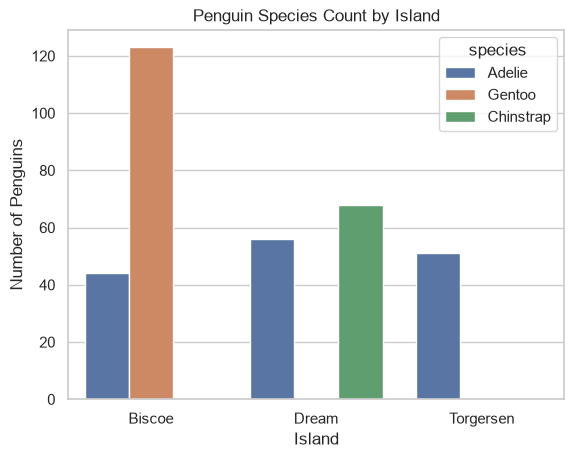

      island    species  count
0     Biscoe     Adelie     44
1     Biscoe     Gentoo    123
2      Dream     Adelie     56
3      Dream  Chinstrap     68
4  Torgersen     Adelie     51
island
Biscoe       167
Dream        124
Torgersen     51
dtype: int64
species    Adelie  Chinstrap  Gentoo
island                              
Biscoe       26.3        0.0    73.7
Dream        45.2       54.8     0.0
Torgersen   100.0        0.0     0.0


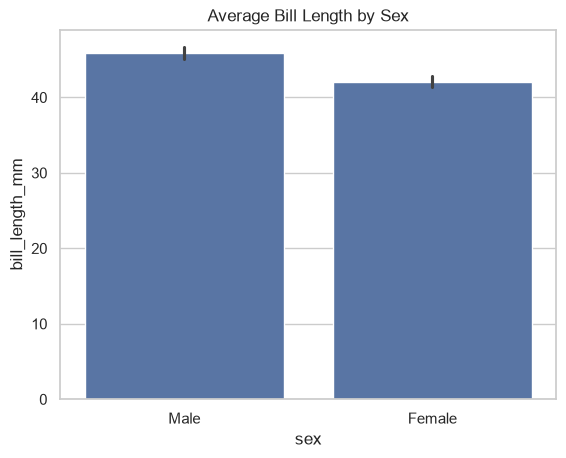

0.8712017673060112


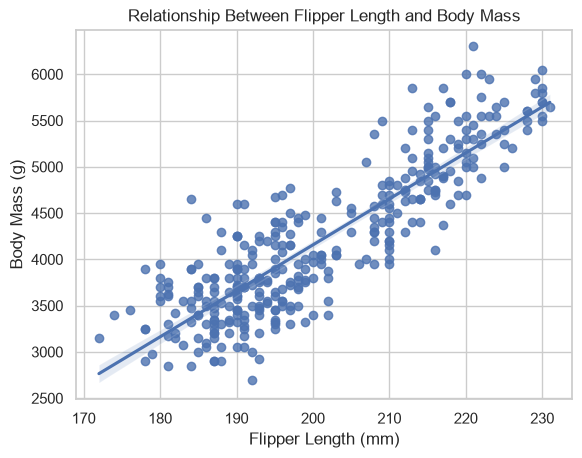

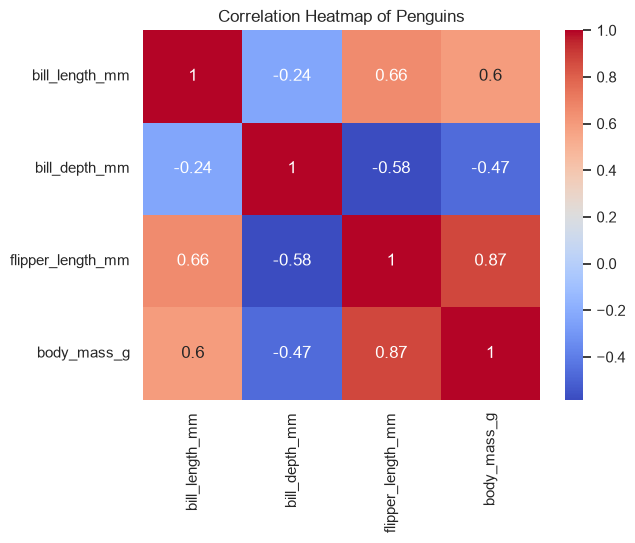

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display

# Set the plot style to make charts easier to read
sns.set_theme(style="whitegrid")

# Load the dataset from the CSV file
try:
    df = pd.read_csv("penguins.csv")

# If the CSV file does not exist, load the Penguins dataset
# from Seaborn and save it as a CSV file
except FileNotFoundError:
    sns.load_dataset("penguins").to_csv("penguins.csv", index=False)
    df = pd.read_csv("penguins.csv")

# Inspect the dataset dimensions (rows and columns)
print(df.shape)

# Check column names, data types, and non-missing values
df.info()

# View summary statistics of numerical columns
# Round the values to one decimal place for readability
print(df.describe().round(1))

# Count missing values in each column
print(df.isna().sum())

# Display all rows that contain at least one missing value
display(df[df.isna().any(axis=1)])

# Display rows that have five or more missing values
# These rows may contain too little information for analysis
display(df[df.isna().sum(axis=1) >= 5])

# Remove rows with index labels 3 and 339
# These rows have five missing values, leaving only species and island
# The decision is to exclude them from the analysis
df = df.drop(index=[3, 339])

# Check the updated dataset dimensions after removing the rows
print(df.shape)

print(df.isna().sum())
display(df[df["sex"].isna()])

df.duplicated().sum()

print(df["species"].unique())
print(df["island"].unique())
print(df["sex"].unique())

counts = df.groupby(["island", "species"]).size().reset_index(name="count")
print(counts)
sns.barplot(data=counts, x="island", y="count", hue="species")
plt.title("Penguin Species Count by Island")
plt.xlabel("Island")
plt.ylabel("Number of Penguins")
plt.savefig("species_by_island.png", bbox_inches="tight", dpi=300)
plt.show()
print(counts)
island_counts = df.groupby("island").size()
print(island_counts)
species_percentage = pd.crosstab(
    df["island"],
    df["species"],
    normalize="index"
) * 100

print(species_percentage.round(1))


df.groupby("sex")["bill_length_mm"].mean()
sns.barplot(data=df,x="sex",y="bill_length_mm")
plt.title("Average Bill Length by Sex")
plt.savefig("bill_length_by_sex.png", bbox_inches="tight", dpi=300)
plt.show()

print(df["flipper_length_mm"].corr(df["body_mass_g"]))

sns.regplot(data=df,x="flipper_length_mm",y="body_mass_g")
plt.title("Relationship Between Flipper Length and Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")

plt.savefig("flipper_vs_body_mass.png", bbox_inches="tight", dpi=300)
plt.show()

numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Penguins")
plt.show()
